In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/kaushaltiwari/tiny-shakespeare/tiny-shakespeare.txt


In [2]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [3]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torch.utils.tensorboard import SummaryWriter
from pathlib import Path

path = "/kaggle/input/datasets/kaushaltiwari/tiny-shakespeare/tiny-shakespeare.txt"
file = Path(path)

device = "cuda" if torch.cuda.is_available() else "cpu"
# print(torch.cuda.get_device_properties())

with file.open("r") as f:
    txt = f.read()

In [4]:
vocab = sorted(list(set(txt)))
stoi = {v:k for k, v in enumerate(vocab)}
itos = {v:k for k, v in stoi.items()}

encoder = lambda s: [stoi[c] for c in s]
decoder = lambda l: "".join([itos[t] for t in l])

data = torch.tensor(encoder(txt), dtype=torch.long)
f"{len(data)/1_000_000:.2f} M tokens"

'1.12 M tokens'

In [14]:
n1 = int(data.shape[0] * 0.9)
# n2 = int(data.shape[0] * 0.9)

train_data = data[:n1]
valid_data = data[n1:]

print(len(train_data)/1_000,"K", len(valid_data)/1000, "K")

1003.854 K 111.54 K


In [15]:
def build_ds(data, batch_size, block_size):
    
    ix = torch.randint(0, len(data) - block_size, (batch_size, ))
    X = torch.stack([data[i:i+block_size] for i in ix])
    Y = torch.stack([data[i+1:i+block_size+1] for i in ix])
    
    return  X, Y

In [16]:
import torch
import torch.nn as nn


class RotatoryPositionalEncoding(nn.Module):

    def __init__(self, d_model, max_len = 50000):
        super().__init__()
        pos = torch.arange(0, max_len).unsqueeze(1)
        ix = torch.arange(0, d_model//2).unsqueeze(0)
        omega = 1e4 ** (-2 * ix/d_model)
        angles = pos * omega
        self.register_buffer("cos", angles.cos())
        self.register_buffer("sin", angles.sin())

    def forward(self, x):
        T= x.shape[-2]
        cos, sin = self.cos[:T], self.sin[:T]

        X, Y = x[..., 0::2], x[..., 1::2] # x-ords, y-ords for every token

        Xn =  X * cos[:T] - Y * sin[:T] # [ cosQ -sinQ ]  [X]
        Yn =  X * sin[:T] + Y * cos[:T] # [ sinQ cosQ ] [Y]
        
        out = torch.empty_like(x)
        out[..., 0::2] = Xn
        out[..., 1::2] = Yn

        return out
        

class GroupedQueryAttention(nn.Module):

    def __init__(self, block_size, d_model, heads, groups, dropout):
        super().__init__()
        assert d_model % heads == 0 and heads % groups == 0, "Error: Check d_model, heads, groups size."
        
        self.hs = d_model // heads
        self.rps = heads // groups
        self.H = heads
        self.G = groups
        
        self.Wqs = nn.Linear(d_model, heads  * self.hs) # C, H * hs(C//H)
        self.Wks = nn.Linear(d_model, groups * self.hs) # C, G * hs
        self.Wvs = nn.Linear(d_model, groups * self.hs) # C, G * hs
        self.Wo = nn.Linear(heads * self.hs, d_model)
        self.rope = RotatoryPositionalEncoding(self.hs, block_size)
        
        self.dropout = nn.Dropout(dropout)

        self.register_buffer("mask", torch.tril(torch.ones(block_size, block_size, dtype=bool)))

    def forward(self, x):
        B, T, _ = x.shape # Batch, block_size, d_models (B, T, C)

        Q = self.Wqs(x).view(B, T, self.H, self.hs).transpose(1, 2) # B, T, H * hs
        K = self.Wks(x).view(B, T, self.G, self.hs).transpose(1, 2) # B, T, G * hs
        V = self.Wvs(x).view(B, T, self.G, self.hs).transpose(1, 2) # B, T, G * hs

        Q, K = self.rope(Q), self.rope(K)
        K = K.repeat_interleave(self.rps, dim=1) # (B, T, G*hs) --stacked R(H//G)--> (B, T, G*R*hs) --> 
        V = V.repeat_interleave(self.rps, dim=1)

        score = Q @ K.transpose(-2, -1) / self.hs ** 0.5
        score = score.masked_fill(self.mask[:T,  :T]==0, float("-inf"))
        probs = F.softmax(score, dim=-1)
        out = probs @ V
        out = out.transpose(1, 2).contiguous().reshape(B, T, -1)
        out  = self.dropout(self.Wo(out))

        return out
        

class FeedForward(nn.Module):

    def __init__(self, d_model, dropout):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(d_model, 4*d_model),
            nn.ReLU(),
            nn.Linear(4*d_model, d_model),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.layers(x)
        


class TransformerBlock(nn.Module):

    def __init__(self, d_model, n_heads, groups, block_size, dropout):
        super().__init__()
        head_size = d_model // n_heads
        self.gqa = GroupedQueryAttention(block_size, d_model, n_heads, groups, dropout)
        self.ff = FeedForward(d_model, dropout)
        self.ln1 = nn.LayerNorm(d_model)
        self.ln2 = nn.LayerNorm(d_model)

    def forward(self, x):
        x = x + self.gqa(self.ln1(x))
        x = x + self.ff(self.ln2(x))
        return x


class DecoderTransformerModel(nn.Module):

    def __init__(self, vocab_size, block_size, d_model, heads, groups, n_layers, dropout):
        super().__init__()
        self.embeddings = nn.Embedding(vocab_size, d_model)
        self.blocks = nn.Sequential(*[TransformerBlock(d_model, heads, groups, block_size, dropout) for _ in range(n_layers)])
        self.ln = nn.LayerNorm(d_model)
        self.linear = nn.Linear(d_model, vocab_size)
        

        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            # print(isinstance(module,nn.Linear))
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)

        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)


    def forward(self, x, target = None):
        out = self.embeddings(x)
        out = self.blocks(out)
        logits = self.linear(self.ln(out))

        
        B, T, C = logits.shape

        loss = None
        if target is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), target.reshape(-1))

            
        return (logits, loss)

In [24]:
@torch.no_grad()
def estimate(model, data, batch_size, block_size, epoch_iter, device):
    was_training = model.training
    model.eval()
    losses, accs = [], []
    for _ in range(epoch_iter):
        xs, ys = build_ds(data, batch_size, block_size)
        xs, ys = xs.to(device), ys.to(device)
        logits, loss = model(xs, ys)
        acc = (logits.argmax(-1) == ys).float().mean()
        losses.append(loss.item())
        accs.append(acc.item())

    
    model.train(was_training)
    return torch.tensor(losses).mean().item(), torch.tensor(accs).mean().item()

In [25]:
# --------------------------------DATASET SPECIFIC PARAMETERS-----------------------------------------
block_size = 128 #No of tokens in a single sequence 
batch_size = 64#No of squences go in one pass.
vocab_size = len(vocab)
# --------------------------------MODEL SPECIFIC PARAMETERS-------------------------------------------
dropout = 0.3
d_model = 256
heads = 4
groups = 2
n_layers = 4


model = DecoderTransformerModel(vocab_size, block_size, d_model, heads, groups, n_layers, dropout).to(device)

params = 0
decay = []
no_decay = []
for p in model.parameters():
    if p.dim() >= 2:
        decay.append(p)
    elif p.dim() < 2:
        no_decay.append(p)
    params += (p.nelement())

print(f"Parameters: {params/1e6:.2f}M")
print(f"Size of model: {(4 * params)/1024 ** 2: 0.2f}MB")


from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR as CALR
import matplotlib.pyplot as plt


lr = 3e-4

optimizer = AdamW([
    {"params":decay,"weight_decay":0.1},
    {"params":no_decay,"weight_decay":0.0}],lr=lr, betas=(0.9, 0.95))

Parameters: 2.93M
Size of model:  11.18MB


In [26]:
x_, y_  = build_ds(test_data, batch_size=batch_size, block_size=block_size)
x_, y_ = x_.to(device), y_.to(device)

model.eval()
with torch.no_grad():
    _, loss = model(x_, y_)
    loss, dev = loss.item(), (abs(loss - math.log(65))/math.log(65))*100
model.train()
print(f"Dry Run Loss: {loss:0.2f} | Deviation: {dev:.2f}%")
print("Initialized Correctly" if dev < 0.5 else "Initialized Again")

Dry Run Loss: 4.18 | Deviation: 0.04%
Initialized Correctly


In [27]:
steps_all, loss_all, valid_loss_all, accuracy_all, val_accuracy_all =[], [], [], [], []
checkpoints = torch.load("checkpoints.pth", map_location=device) 
bench_val_loss = checkpoints.get('val_loss', float("inf"))
bench_acc = checkpoints.get('val_acc')
print("Best Val Loss:", bench_val_loss) if bench_val_loss is not None else None
print("Best Val Accuracy:", bench_acc) if bench_acc is not None else None

Best Val Loss: 1.908686876296997
Best Val Accuracy: 0.5235774517059326


In [28]:
import time
from tqdm import tqdm

epochs = 20000
val_epochs = 150
max_iter = 100

scheduler = CALR(optimizer, T_max=epochs)

steps, lossi, valid_lossi, accuracyi, val_accuracyi =[], [], [], [], []
seconds = 0

model.train()
for epoch in tqdm(range(epochs), desc="Training"):
    start = time.time()
    xs, ys = build_ds(train_data, batch_size, block_size)
    xs, ys = xs.to(device), ys.to(device)
    logits, loss = model(xs, ys)

    #-----------------[Optimizer/Loss Calculation]-----------------------------#
    optimizer.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0) #for stablizing grda within particular range if it goes beyond 1.0 it's normalized and adjusted
    optimizer.step()
    scheduler.step()
   
    
    if epoch%max_iter == 0 or epoch == epochs - 1:

        #---------------[ACCURACY/LOSS Calculations]-----------------#
        accuracy = (logits.argmax(dim=-1) == ys).float().mean().item()
        val_loss, val_accuracy = estimate(model, valid_data, batch_size, block_size, val_epochs, device) 
        accuracyi.append(accuracy)
        val_accuracyi.append(val_accuracy)

        #---------------[EPOCHS]-------------------#
        steps.append(epoch)

        #---------------[LOSS]---------------------#
        valid_lossi.append(math.log10(val_loss))
        lossi.append(loss.log10().item())
        
        
        if val_loss < bench_val_loss:
            #------------------[CHECKPOINTS]----------------#
            checkpoints = {
                "model_state_dict": model.state_dict(),
                "optim_state_dict": optimizer.state_dict(),
                "loss": loss.item(),
                "acc": accuracy,
                "val_loss":val_loss,
                "val_acc":val_accuracy,
                "epoch": epoch,
            }
            #-----------------[SAVE]------------------------#
            PATH = "/kaggle/working/checkpoints.pth"
            torch.save(checkpoints, PATH)
            bench_valid_loss = val_loss

        tqdm.write(f"""[{epoch:4d}/{epochs}] | Loss: {loss:.3f} | Accuracy: {accuracy * 100:.1f}% | Val Loss: {val_loss:.3f} | Val Accuracy: {val_accuracy*100:.1f}% | Total Time: {seconds:.2f}(s)""")
        seconds = 0
        
    end = time.time()
    seconds += end - start
    

steps_all += steps
loss_all += lossi
valid_loss_all += valid_lossi
accuracy_all += accuracyi
val_accuracy_all += val_accuracyi
print("Best_val_loss:", bench_valid_loss)

Training:   0%|          | 4/20000 [00:04<4:18:21,  1.29it/s] 

[   0/20000] | Loss: 4.185 | Accuracy: 1.3% | Val Loss: 3.678 | Val Accuracy: 14.9% | Total Time: 0.00(s)


Training:   1%|          | 104/20000 [00:15<2:40:03,  2.07it/s]

[ 100/20000] | Loss: 2.323 | Accuracy: 32.9% | Val Loss: 2.309 | Val Accuracy: 32.6% | Total Time: 10.82(s)


Training:   1%|          | 204/20000 [00:26<2:45:31,  1.99it/s]

[ 200/20000] | Loss: 2.095 | Accuracy: 39.1% | Val Loss: 2.083 | Val Accuracy: 38.6% | Total Time: 11.29(s)


... (392 outputs left out)

Training: 100%|█████████▉| 19904/20000 [41:26<00:52,  1.84it/s]

[19900/20000] | Loss: 1.094 | Accuracy: 65.2% | Val Loss: 1.526 | Val Accuracy: 57.8% | Total Time: 12.50(s)


Training: 100%|██████████| 20000/20000 [41:38<00:00,  8.00it/s]

[19999/20000] | Loss: 1.107 | Accuracy: 64.9% | Val Loss: 1.534 | Val Accuracy: 57.8% | Total Time: 12.38(s)
Best_val_loss: 1.533819556236267


In [29]:
steps_all += steps
loss_all += lossi
valid_loss_all += valid_lossi
accuracy_all += accuracyi
val_accuracy_all += val_accuracyi
print("Best_val_loss:", bench_valid_loss)

Best_val_loss: 1.533819556236267


In [248]:
valid_loss_all.__len__()

402

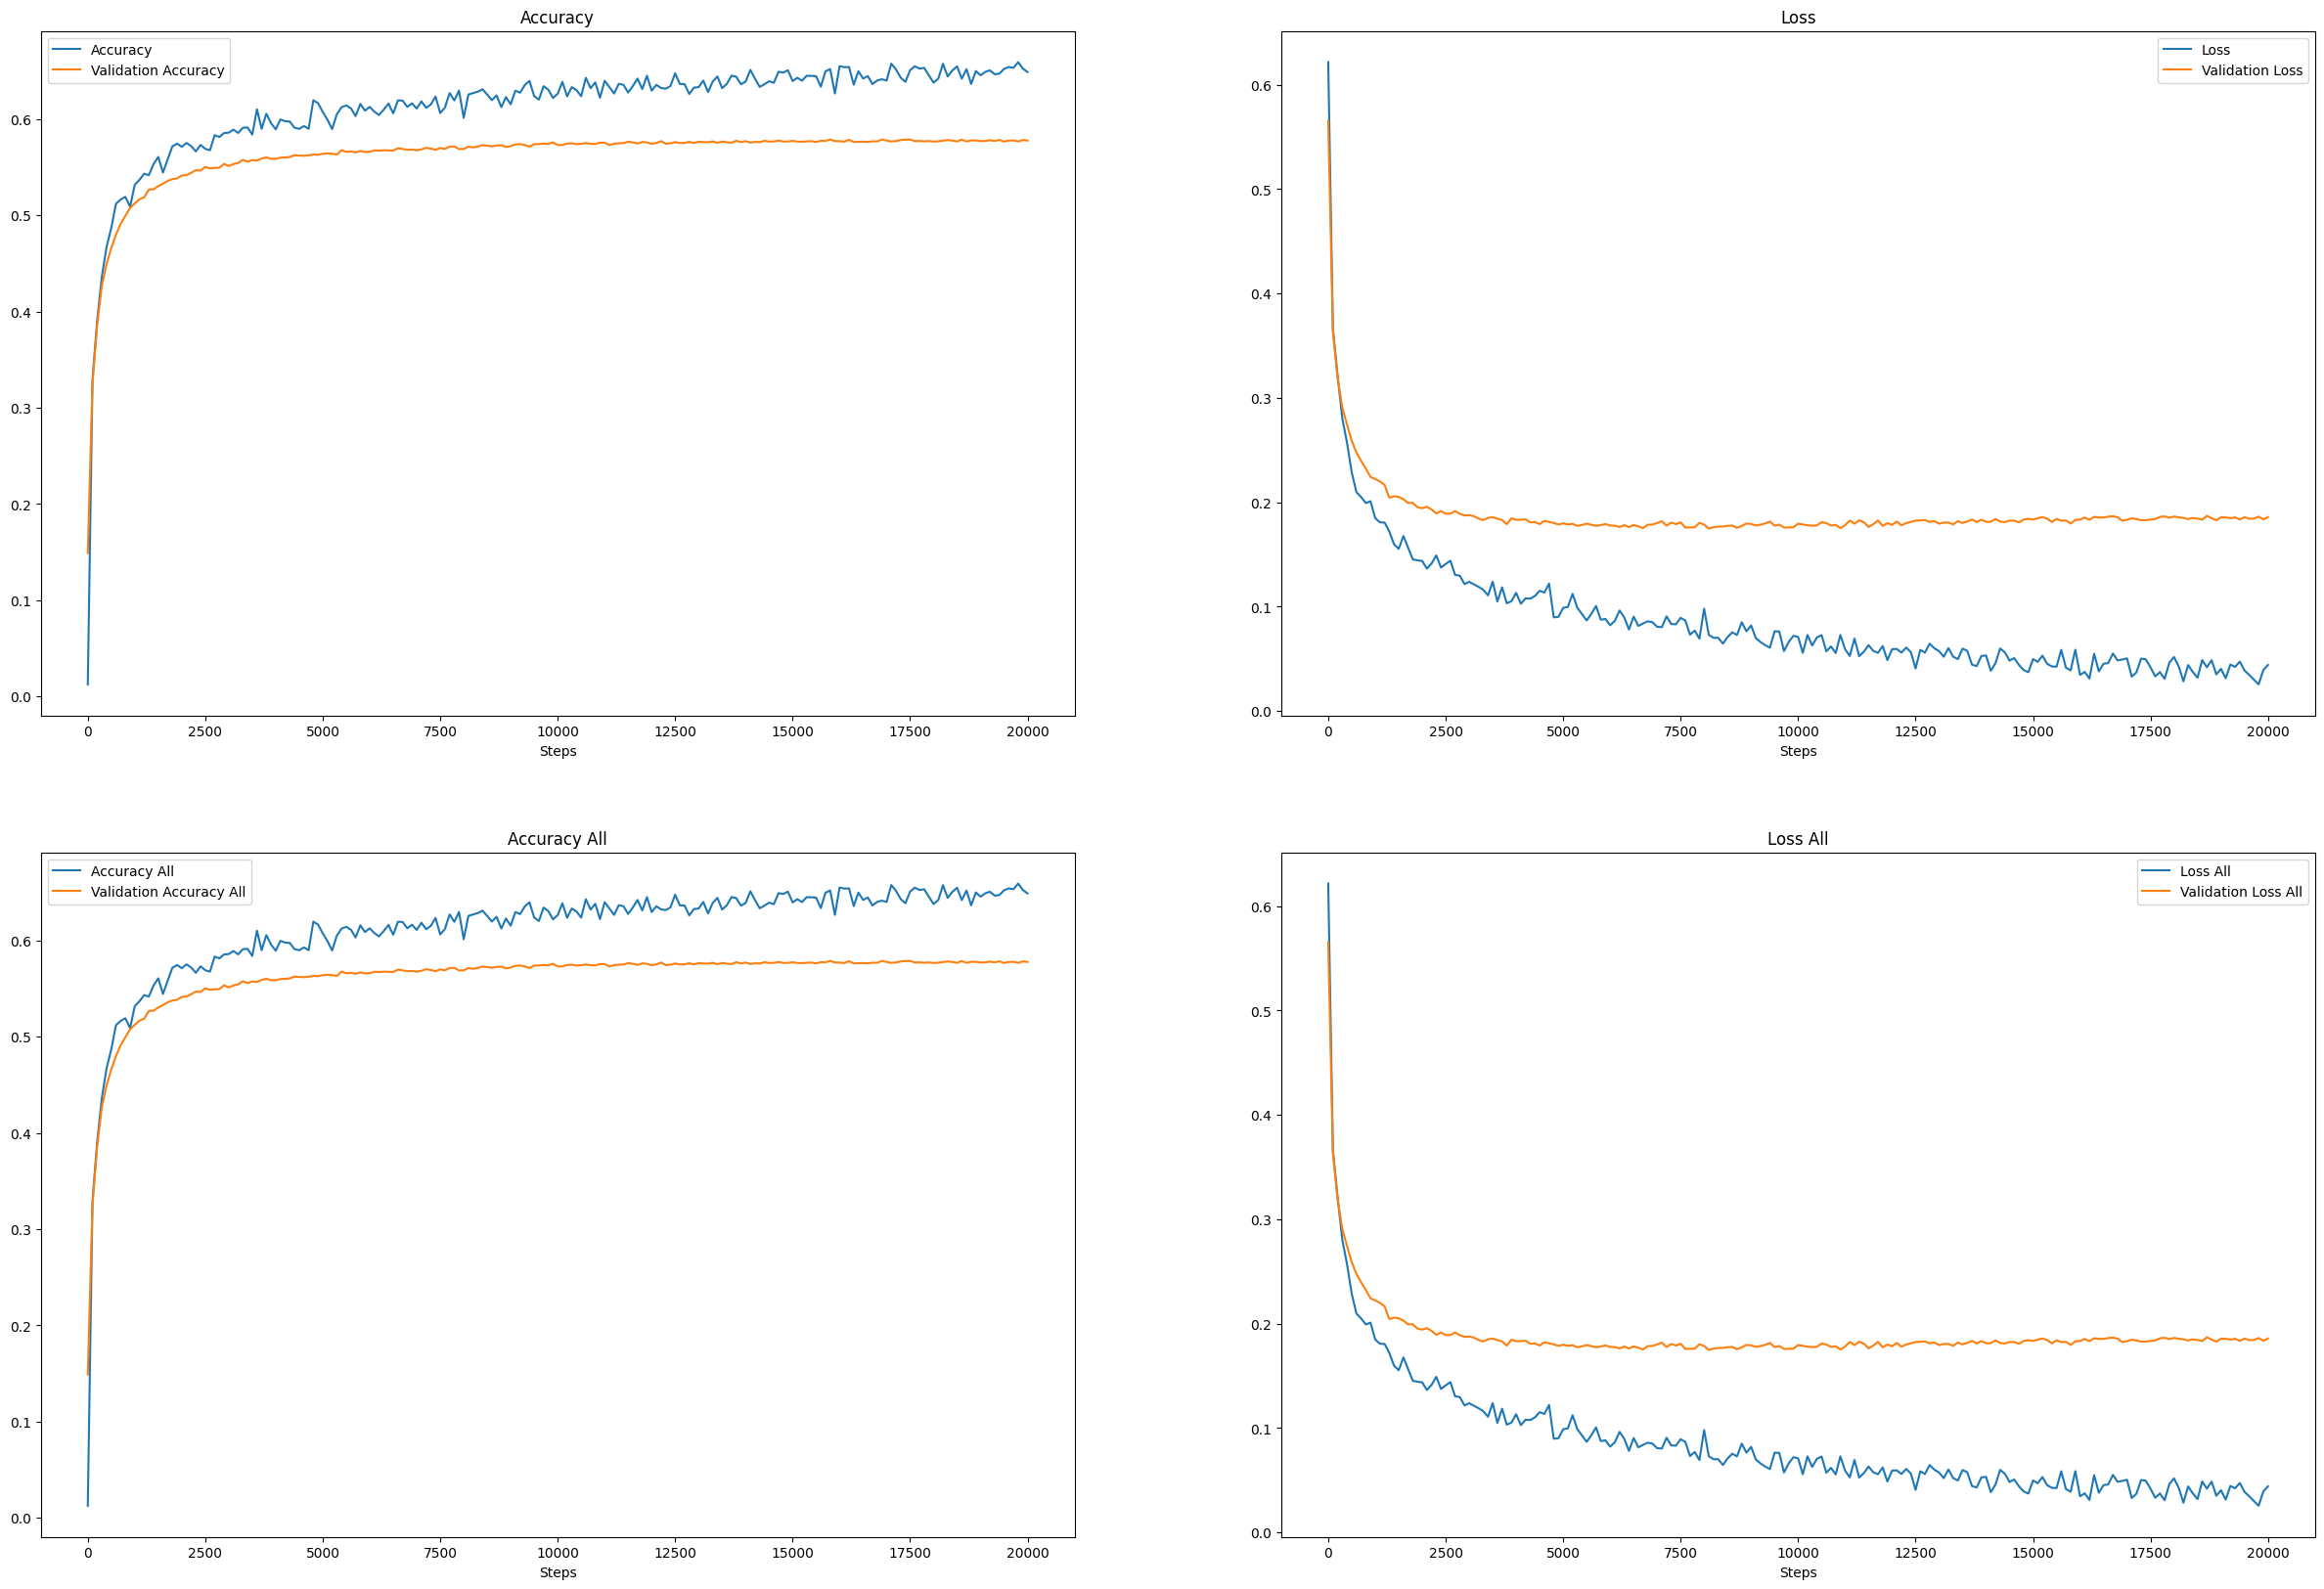

<Figure size 640x480 with 0 Axes>

In [253]:
fig, ax = plt.subplots(2, 2, figsize=(30, 20))

ax[0, 0].plot(steps, accuracyi, label="Accuracy")
ax[0, 0].plot(steps, val_accuracyi, label="Validation Accuracy")
ax[0, 0].set_title("Accuracy")
ax[0, 0].set_xlabel("Steps")
ax[0, 0].legend()


ax[0, 1].plot(steps, lossi, label="Loss")
ax[0, 1].plot(steps, valid_lossi, label="Validation Loss")
ax[0, 1].set_title("Loss")
ax[0, 1].set_xlabel("Steps")
ax[0, 1].legend()


ax[1, 0].plot(steps_all[:201], accuracy_all[:201], label="Accuracy All")
ax[1, 0].plot(steps_all[:201], val_accuracy_all[:201], label="Validation Accuracy All")
ax[1, 0].set_title("Accuracy All")
ax[1, 0].set_xlabel("Steps")
ax[1, 0].legend()


ax[1, 1].plot(steps_all[:201], loss_all[:201], label="Loss All")
ax[1, 1].plot(steps_all[:201], valid_loss_all[:201], label="Validation Loss All")
ax[1, 1].set_title("Loss All")
ax[1, 1].set_xlabel("Steps")
ax[1, 1].legend()


plt.show()
plt.tight_layout()

# other ways of observability
#weight initialization spiked loss to very low loss
#better way to train the model
#hyper parameter tunning

In [52]:
model_path = "/kaggle/working/checkpoints.pth"
checkpoints = torch.load(model_path, map_location=device)
model.load_state_dict(checkpoints["model_state_dict"])
model.eval()

DecoderTransformerModel(
  (embeddings): Embedding(65, 256)
  (blocks): Sequential(
    (0): TransformerBlock(
      (gqa): GroupedQueryAttention(
        (Wqs): Linear(in_features=256, out_features=256, bias=True)
        (Wks): Linear(in_features=256, out_features=128, bias=True)
        (Wvs): Linear(in_features=256, out_features=128, bias=True)
        (Wo): Linear(in_features=256, out_features=256, bias=True)
        (rope): RotatoryPositionalEncoding()
        (dropout): Dropout(p=0.3, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=256, out_features=1024, bias=True)
          (1): ReLU()
          (2): Linear(in_features=1024, out_features=256, bias=True)
          (3): Dropout(p=0.3, inplace=False)
        )
      )
      (ln1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
      (ln2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
    )
    (1): TransformerBlock(
      (gqa): GroupedQueryAttention(

In [53]:
print(f"Loss: {checkpoints["loss"]:.2f}")
print(f"Val Loss: {checkpoints["val_loss"]:.2f}")
print(f"Accuracy: {checkpoints["acc"]*100:.2f}%")
print(f"Val Accuracy: {checkpoints["val_acc"]*100:.2f}%")

Loss: 1.11
Val Loss: 1.53
Accuracy: 64.89%
Val Accuracy: 57.77%


# Questions?

> 1. How to improve the context window size? (mid training but really how?)

In [244]:


T = 0.7 #randomness
topk = 10 #occurances of top 10 most probable tokens


output_tokens = 0
max_new_tokens = 10000
context_window = 127 # can't be greater than block_size over which model is trained. this is the context window we thought of.

ix = torch.randint(0, valid_data.size(0) - context_window, (1, ))
starter = decoder(test_data[ix:ix+context_window].tolist())
context = torch.tensor([encoder(starter)], device=device)

model.eval()

print("Prompt:", starter)
with torch.no_grad():
    while True:
  
        logits, _ = model(context[:, -context_window:]) #(B, tokens_block)
        logits = logits[:, -1, :]/T # Introduced Randomness

        tops, _ = torch.topk(logits, topk) # find topk most probable tokens logits
        logits[logits < tops[:, [-1]]] == float('-inf') #the occurance of rest of which is not admired theremore leave them to something which won't be counted
        # therefore set to -inf
        probs = F.softmax(logits, dim=-1)
        x = torch.multinomial(probs, num_samples=1, generator=g) # so out of probability distribution for topk possibilities choose 1 possibility.
        output_tokens += 1
        context = torch.cat([context, x], dim=1)
        print(decoder(x[0].tolist()), end="")
        
        if output_tokens == max_new_tokens:
            break
        

Prompt: f my hidden power
Than let him so be lost. O most kind maid,
It was the swift celerity of his death,
Which I did think with slo
wer from my heart,
And all my fathers' sons of soul to-day.

KING RICHARD III:
Norfolk, thou hast no less than my soul's love.
Where's Richard Clarence? thy soul doth remember
But thou shalt hear thee, I will make you bite you
marry and be but a charge. See, he's a thousand lives
of you to this person.

SICINIUS:
Now, my good lord.

CORIOLANUS:
You are true,
To be an used in piece of the white youth
And bid you hear your honour have disposed
By this your own commonwealth.

COMINIUS:
They say you are a man: and if you be your love
To say 'I'!' 'Tis protest as it were as he.

BRUTUS:
If he be penitent,
The instruct him of him?

SICINIUS:
The guests of his ford.

First Senator:
As if you hear you say, you shall have seen too heavy
well with you.

CORIOLANUS:
Hear me not you so?

MENENIUS:
Now, by your lordship did seem me thence, for you must
be but a sec